In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

print("TruthLens — NLP & Feature Engineering")
print("Libraries imported successfully!")

TruthLens — NLP & Feature Engineering
Libraries imported successfully!


In [2]:
file_path = "../data/xfact_train.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset loaded successfully!
Shape: (19079, 17)

Columns:
['language', 'site', 'evidence_1', 'evidence_2', 'evidence_3', 'evidence_4', 'evidence_5', 'link_1', 'link_2', 'link_3', 'link_4', 'link_5', 'claimDate', 'reviewDate', 'claimant', 'claim', 'label']


In [3]:
print("Total claims:", len(df))

print("\nMissing claims:")
print(df["claim"].isna().sum())

print("\nClaim text examples:")
for i, row in df[["language", "claim"]].dropna().sample(5, random_state=42).iterrows():
    print(f"\nLanguage: {row['language']}")
    print(f"Claim: {row['claim']}")
    print("-" * 80)

Total claims: 19079

Missing claims:
0

Claim text examples:

Language: es
Claim: “Formosa es la provincia que más invierte por alumno en el país”
--------------------------------------------------------------------------------

Language: pt
Claim: AVISO IMPORTANTE PARA QUEM DIRIGE: Não higienize a chave do carro com álcool em gel ou líquido 70%. Muitos acidentes estão ocorrendo por isso. O incêndio que houve em uma garagem em Belém, foi decorrente de uma chave de carro higienizada com álcool gel 70%, que ao ser colocada na ignição do veículo gerou uma faísca e acabou incendiando o veículo
--------------------------------------------------------------------------------

Language: id
Claim: “diguyur air, bagian dari Islamophobi”
--------------------------------------------------------------------------------

Language: it
Claim: «Il nostro Paese è ancora oggi un Paese di emigrazione più di quanto non sia un Paese di immigrazione»
---------------------------------------------------------

In [4]:
df["claim_length"] = df["claim"].str.split().str.len()

language_length = (
    df.groupby("language")["claim_length"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("mean", ascending=False)
    .round(2)
)

display(language_length)

,count,mean,median,min,max
language,,,,,
sr,624,30.04,25.0,3,118
ro,698,21.84,23.0,5,31
pl,1325,21.14,18.0,3,109
ta,1097,21.09,17.0,1,127
hi,845,16.55,16.0,5,68
pt,5601,16.13,13.0,1,158
it,943,15.91,11.0,1,97
tr,858,15.83,14.0,4,46
ar,1567,14.91,13.0,4,70


In [5]:
longest_claims = (
    df.nlargest(5, "claim_length")
    [["language", "claim_length", "claim"]]
)

for index, row in longest_claims.iterrows():
    print(f"\nLanguage: {row['language']}")
    print(f"Words: {row['claim_length']}")
    print(f"Claim: {row['claim'][:500]}")
    print("-" * 80)


Language: de
Words: 597
Claim: Von PS - 18. Oktober 2018 7 3446 Share Immer dann, wenn man denkt, es sei nun wirklich nicht mehr möglich, den grünen Irrsinn noch weiter zu steigern, wird man eines Schlechteren belehrt. So sah sich nun der Eigentümerverband Haus & Grund gezwungen, seinen 900.000 Mitgliedern zu empfehlen, die Namensschilder bei vermieteten Wohnungen zu entfernen! Der Grund: Die Mieter könnten sich durch die Klingelschilder in ihrer Privatsphäre verletzt sehen und den Vermieter dann verklagen – Bußgelder bis zu 
--------------------------------------------------------------------------------

Language: pt
Words: 158
Claim: A classe média afivelou as malas. Vai fazer uma longa viagem e não sabe se volta (isso, se puder retornar!). Ela parte deixando para trás a ilusão que pertencia a elite e que imitando hábitos e trejeitos de uma casta superior poderia posar de rica. Se despede do apartamento de três quartos financiado na zona nobre da cidade. Na garagem fica o carro bac

In [6]:
duplicate_count = df["claim"].duplicated().sum()

unique_claims = df["claim"].nunique()

print("Total claims:", len(df))
print("Unique claims:", unique_claims)
print("Exact duplicate claims:", duplicate_count)

print(
    "Duplicate percentage:",
    round((duplicate_count / len(df)) * 100, 2),
    "%"
)

Total claims: 19079
Unique claims: 19032
Exact duplicate claims: 47
Duplicate percentage: 0.25 %


In [7]:
duplicate_rows = df[
    df.duplicated(subset="claim", keep=False)
].sort_values("claim")

display(
    duplicate_rows[
        ["claim", "language", "label", "site"]
    ].head(20)
)

,claim,language,label,site
15686,2011 წელს წინა ხელისუფლების მიერ შეტანილმა სარ...,ka,false,factcheck.ge
16262,2011 წელს წინა ხელისუფლების მიერ შეტანილმა სარ...,ka,false,factcheck.ge
5936,"2012 წელთან შედარებით, დოლარში საქართველოს ეკო...",ka,partly true/misleading,factcheck.ge
13390,"2012 წელთან შედარებით, დოლარში საქართველოს ეკო...",ka,partly true/misleading,factcheck.ge
2957,2015 წლის ბიუჯეტი გადაჭარბებით შესრულდა და ეს ...,ka,partly true/misleading,factcheck.ge
3557,2015 წლის ბიუჯეტი გადაჭარბებით შესრულდა და ეს ...,ka,partly true/misleading,factcheck.ge
1089,"2019 წლის დასაწყისში ვამბობდით, რომ ახალი საი...",ka,complicated/hard to categorise,factcheck.ge
5470,"2019 წლის დასაწყისში ვამბობდით, რომ ახალი საი...",ka,complicated/hard to categorise,factcheck.ge
3940,"Der Vizepräsident der EU-Kommission fordert, m...",de,false,correctiv.org
7514,"Der Vizepräsident der EU-Kommission fordert, m...",de,false,correctiv.org


In [8]:
duplicate_analysis = (
    df[df.duplicated(subset="claim", keep=False)]
    .groupby("claim")
    .agg(
        languages=("language", "nunique"),
        labels=("label", "nunique"),
        sites=("site", "nunique"),
        records=("claim", "size")
    )
)

print("Duplicate claim groups:", len(duplicate_analysis))

print(
    "Groups with different labels:",
    (duplicate_analysis["labels"] > 1).sum()
)

print(
    "Groups with different languages:",
    (duplicate_analysis["languages"] > 1).sum()
)

print(
    "Groups with different fact-checking sites:",
    (duplicate_analysis["sites"] > 1).sum()
)

Duplicate claim groups: 41
Groups with different labels: 2
Groups with different languages: 0
Groups with different fact-checking sites: 0


In [9]:
conflicting_claims = duplicate_analysis[
    duplicate_analysis["labels"] > 1
].index

conflict_details = df[
    df["claim"].isin(conflicting_claims)
][["claim", "language", "label", "site", "claimDate", "reviewDate"]]

display(conflict_details)

,claim,language,label,site,claimDate,reviewDate
1394,[Não recebo] nem verba indenizatória,pt,mostly true,piaui.folha.uol.com.br,2018-08-16T07:10:42Z,2018-08-16T07:10:42Z
2692,Ein Buch mit vulgären Begriffen für Sex wird i...,de,partly true/misleading,correctiv.org,2018-12-09T23:00:00Z,2019-02-28T09:08:22Z
12604,[Não recebo] nem verba indenizatória,pt,false,piaui.folha.uol.com.br,2018-06-06T07:00:19Z,2018-06-06T07:00:19Z
15337,Ein Buch mit vulgären Begriffen für Sex wird i...,de,false,correctiv.org,none,2019-02-28T08:45:48Z


In [10]:
evidence_columns = [
    "label",
    "claimDate",
    "reviewDate",
    "evidence_1",
    "evidence_2",
    "link_1",
    "link_2"
]

for claim in conflicting_claims:
    print("\n" + "=" * 90)
    print("CONFLICTING CLAIM:")
    print(claim)

    display(
        df.loc[
            df["claim"].eq(claim),
            evidence_columns
        ].T
    )


CONFLICTING CLAIM:
Ein Buch mit vulgären Begriffen für Sex wird in deutschen Schulen benutzt.


,2692,15337
label,partly true/misleading,false
claimDate,2018-12-09T23:00:00Z,none
reviewDate,2019-02-28T09:08:22Z,2019-02-28T08:45:48Z
evidence_1,Die Liste lateinischer Lehn- und Fremdwörter i...,Die Liste lateinischer Lehn- und Fremdwörter i...
evidence_2,Für die im Mittelalter von der Bevölkerungsmeh...,Für die im Mittelalter von der Bevölkerungsmeh...
link_1,https://de.wikipedia.org/wiki/Liste_lateinisch...,https://de.wikipedia.org/wiki/Liste_lateinisch...
link_2,https://de.wikipedia.org/wiki/Vulg%C3%A4rsprache,https://de.wikipedia.org/wiki/Vulg%C3%A4rsprache



CONFLICTING CLAIM:
[Não recebo] nem verba indenizatória


,1394,12604
label,mostly true,false
claimDate,2018-08-16T07:10:42Z,2018-06-06T07:00:19Z
reviewDate,2018-08-16T07:10:42Z,2018-06-06T07:00:19Z
evidence_1,"Jun 6, 2018 — “[Não recebo] nem verba indeniza...","Jun 6, 2018 — “[Não recebo] nem verba indeniza..."
evidence_2,"Jun 19, 2018 — Dessa forma, a contribuição soc...","Jun 19, 2018 — Dessa forma, a contribuição soc..."
link_1,https://piaui.folha.uol.com.br/lupa/2018/06/06...,https://piaui.folha.uol.com.br/lupa/2018/06/06...
link_2,https://ibgpt.com.br/a-nao-incidencia-do-inss-...,https://ibgpt.com.br/a-nao-incidencia-do-inss-...


In [11]:
german_claim = [
    claim for claim in conflicting_claims
    if df.loc[df["claim"].eq(claim), "language"].iloc[0] == "de"
][0]

display(
    df.loc[
        df["claim"].eq(german_claim),
        [
            "label",
            "claimDate",
            "reviewDate",
            "evidence_1",
            "evidence_2",
            "link_1",
            "link_2"
        ]
    ].T
)

,2692,15337
label,partly true/misleading,false
claimDate,2018-12-09T23:00:00Z,none
reviewDate,2019-02-28T09:08:22Z,2019-02-28T08:45:48Z
evidence_1,Die Liste lateinischer Lehn- und Fremdwörter i...,Die Liste lateinischer Lehn- und Fremdwörter i...
evidence_2,Für die im Mittelalter von der Bevölkerungsmeh...,Für die im Mittelalter von der Bevölkerungsmeh...
link_1,https://de.wikipedia.org/wiki/Liste_lateinisch...,https://de.wikipedia.org/wiki/Liste_lateinisch...
link_2,https://de.wikipedia.org/wiki/Vulg%C3%A4rsprache,https://de.wikipedia.org/wiki/Vulg%C3%A4rsprache


In [12]:
df["is_duplicate_claim"] = df.duplicated(
    subset="claim",
    keep=False
)

df["has_label_conflict"] = (
    df.groupby("claim")["label"]
    .transform("nunique")
    .gt(1)
)

print("Duplicate claim records:")
print(df["is_duplicate_claim"].sum())

print("\nRecords belonging to conflicting-label groups:")
print(df["has_label_conflict"].sum())

print("\nOriginal dataset shape:", df.shape)

Duplicate claim records:
88

Records belonging to conflicting-label groups:
4

Original dataset shape: (19079, 20)


In [13]:
import re
import unicodedata

df["claim_normalized"] = df["claim"].apply(
    lambda text: re.sub(
        r"\s+",
        " ",
        unicodedata.normalize("NFC", text)
    ).strip()
)

changed_claims = (
    df["claim"] != df["claim_normalized"]
).sum()

print("Original claims:", len(df))
print("Normalized claims:", df["claim_normalized"].notna().sum())
print("Claims changed during normalization:", changed_claims)

print("\nOriginal example:")
print(df["claim"].iloc[0])

print("\nNormalized example:")
print(df["claim_normalized"].iloc[0])

Original claims: 19079
Normalized claims: 19079
Claims changed during normalization: 194

Original example:
Son 50 yılın siyasi tarihine bakın, tek başına iktidarlardaki Türkiye’nin büyüme oranı, koalisyon dönemlerindekinin iki katıdır.

Normalized example:
Son 50 yılın siyasi tarihine bakın, tek başına iktidarlardaki Türkiye’nin büyüme oranı, koalisyon dönemlerindekinin iki katıdır.


In [14]:
normalized_duplicates = df[
    df.duplicated(
        subset="claim_normalized",
        keep=False
    )
]

normalized_groups = (
    normalized_duplicates
    .groupby("claim_normalized")
    .agg(
        records=("claim_normalized", "size"),
        labels=("label", "nunique")
    )
)

print(
    "Duplicate records after normalization:",
    len(normalized_duplicates)
)

print(
    "Duplicate groups after normalization:",
    len(normalized_groups)
)

print(
    "Groups with conflicting labels:",
    (normalized_groups["labels"] > 1).sum()
)

Duplicate records after normalization: 88
Duplicate groups after normalization: 41
Groups with conflicting labels: 2


In [15]:
df["normalized_word_count"] = (
    df["claim_normalized"].str.split().str.len()
)

length_summary = (
    df.groupby("language")["normalized_word_count"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("mean", ascending=False)
)

display(length_summary)

,count,mean,median
language,,,
sr,624,30.04,25.0
ro,698,21.84,23.0
pl,1325,21.14,18.0
ta,1097,21.09,17.0
hi,845,16.55,16.0
pt,5601,16.13,13.0
it,943,15.91,11.0
tr,858,15.83,14.0
ar,1567,14.91,13.0


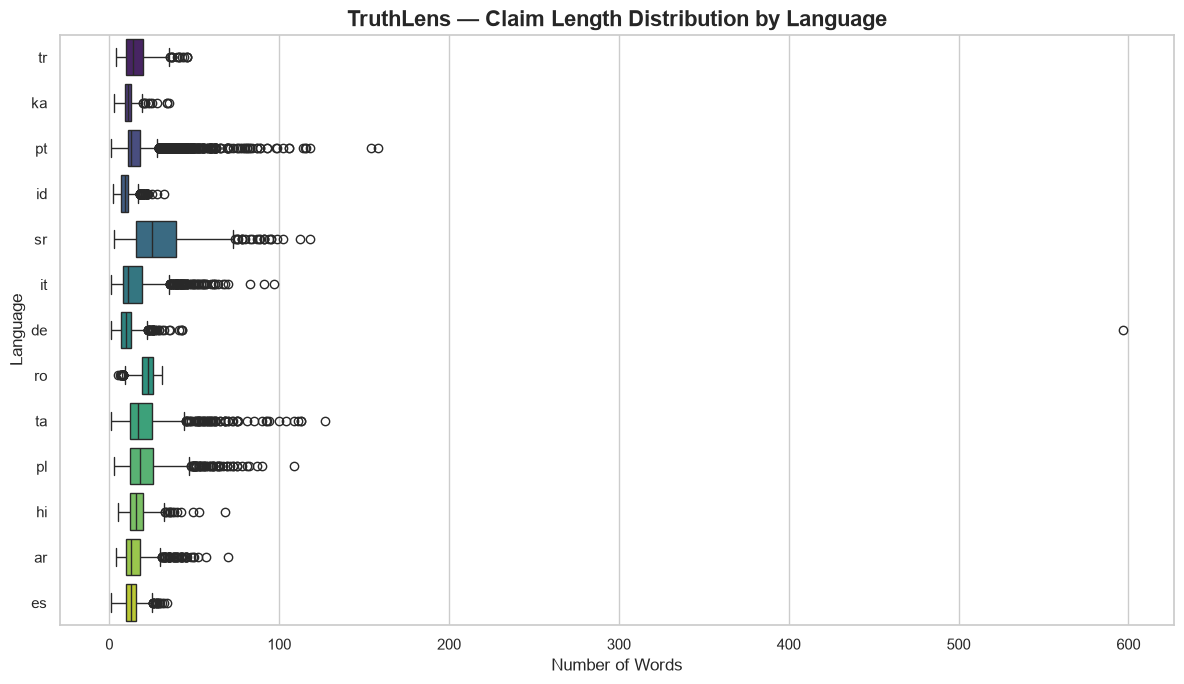

In [16]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df,
    x="normalized_word_count",
    y="language",
    hue="language",
    palette="viridis",
    legend=False,
    showfliers=True
)

plt.title(
    "TruthLens — Claim Length Distribution by Language",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Number of Words")
plt.ylabel("Language")

plt.tight_layout()
plt.show()

In [17]:
language_distribution = (
    df["language"]
    .value_counts()
    .rename_axis("language")
    .reset_index(name="total_claims")
)

language_distribution["percentage"] = (
    language_distribution["total_claims"]
    / len(df) * 100
).round(2)

display(language_distribution)

,language,total_claims,percentage
0,pt,5601,29.36
1,id,2231,11.69
2,ar,1567,8.21
3,ka,1529,8.01
4,pl,1325,6.94
5,ta,1097,5.75
6,es,1049,5.50
7,it,943,4.94
8,tr,858,4.50
9,hi,845,4.43


In [18]:
df["claim_char_count"] = (
    df["claim_normalized"].str.len()
)

print("Character count feature created!")

display(
    df.groupby("language")["claim_char_count"]
    .agg(["mean", "median", "min", "max"])
    .round(2)
    .sort_values("mean", ascending=False)
)

Character count feature created!


,mean,median,min,max
language,,,,
sr,179.96,155.0,25,706
ta,178.04,147.0,10,1062
pl,140.67,121.0,20,678
ro,130.74,146.0,31,157
tr,112.21,101.0,32,337
pt,96.11,75.0,15,917
it,95.85,66.0,12,567
ka,91.08,103.0,24,272
ar,89.23,80.0,21,362


In [19]:
df["avg_chars_per_word"] = (
    df["claim_char_count"] /
    df["normalized_word_count"].replace(0, np.nan)
)

print("Average characters per word feature created!")

display(
    df.groupby("language")["avg_chars_per_word"]
    .mean()
    .round(2)
    .sort_values(ascending=False)
)

Average characters per word feature created!


language
ta    8.50
ka    8.40
de    7.61
tr    7.16
id    6.85
pl    6.68
it    6.22
sr    6.12
ro    6.07
pt    6.05
ar    6.01
es    5.85
hi    5.10
Name: avg_chars_per_word, dtype: float64

In [20]:
def count_unicode_features(text):
    punctuation = sum(
        unicodedata.category(char).startswith("P")
        for char in text
    )

    numbers = sum(
        unicodedata.category(char).startswith("N")
        for char in text
    )

    return pd.Series([punctuation, numbers])


df[["punctuation_count", "number_count"]] = (
    df["claim_normalized"]
    .apply(count_unicode_features)
)

print("Punctuation and number features created!")

display(
    df[
        ["claim", "punctuation_count", "number_count"]
    ].head(10)
)

Punctuation and number features created!


,claim,punctuation_count,number_count
0,"Son 50 yılın siyasi tarihine bakın, tek başına...",4,2
1,"""ევროპული ღირებულებები"" - იტალიის სამაშველო სა...",6,0
2,"Aqui em São Paulo, nós estamos com 2,7 milhões...",4,8
3,"ირაკლი ხახუბია, ""ნაციონალური მოძრაობის"" სპონსო...",6,0
4,Zumi Zola Jalan-Jalan Di Bandara Soekarno-Hatta,2,0
5,"No Twitter, o PSD escreve que a taxa de desemp...",7,0
6,„U prvim mesecima 2011. godine imamo odlične p...,5,6
7,Quanto spendono Italia ed Europa per l’immigra...,1,0
8,Video “DETIK DETIK MA'RUF AMIN MUNDUR & DIGANT...,4,0
9,Alfamart Menyumbangkan 6000 Kupon Untuk Memban...,1,6


In [21]:
from sklearn.model_selection import StratifiedGroupKFold

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        df["claim_normalized"],
        df["label"],
        groups=df["claim_normalized"]
    )
)

X_train = df.iloc[train_idx]["claim_normalized"]
X_test = df.iloc[test_idx]["claim_normalized"]

y_train = df.iloc[train_idx]["label"]
y_test = df.iloc[test_idx]["label"]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training labels:", y_train.nunique())
print("Testing labels:", y_test.nunique())

Training records: 15263
Testing records: 3816
Training labels: 7
Testing labels: 7


In [22]:
print("TRAINING LABEL DISTRIBUTION")
display(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("TESTING LABEL DISTRIBUTION")
display(
    y_test.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

TRAINING LABEL DISTRIBUTION


label
false                             39.39
partly true/misleading            22.85
true                              21.39
mostly true                        7.23
mostly false                       4.44
complicated/hard to categorise     2.83
other                              1.87
Name: proportion, dtype: float64

TESTING LABEL DISTRIBUTION


label
false                             39.39
partly true/misleading            22.85
true                              21.38
mostly true                        7.23
mostly false                       4.45
complicated/hard to categorise     2.83
other                              1.86
Name: proportion, dtype: float64

In [23]:
print("TESTING LABEL DISTRIBUTION")

display(
    y_test.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

TESTING LABEL DISTRIBUTION


label
false                             39.39
partly true/misleading            22.85
true                              21.38
mostly true                        7.23
mostly false                       4.45
complicated/hard to categorise     2.83
other                              1.86
Name: proportion, dtype: float64

In [24]:
print("Training and testing identical:",
      y_train.equals(y_test))

print("\nTraining records:", len(y_train))
print("Testing records:", len(y_test))

print("\nTraining label counts:")
display(y_train.value_counts())

print("\nTesting label counts:")
display(y_test.value_counts())

Training and testing identical: False

Training records: 15263
Testing records: 3816

Training label counts:


label
false                             6012
partly true/misleading            3487
true                              3264
mostly true                       1104
mostly false                       678
complicated/hard to categorise     432
other                              286
Name: count, dtype: int64


Testing label counts:


label
false                             1503
partly true/misleading             872
true                               816
mostly true                        276
mostly false                       170
complicated/hard to categorise     108
other                               71
Name: count, dtype: int64

In [25]:
print("Training and testing identical:", y_train.equals(y_test))
print("Training records:", len(y_train))
print("Testing records:", len(y_test))
print("Total records:", len(y_train) + len(y_test))

Training and testing identical: False
Training records: 15263
Testing records: 3816
Total records: 19079


In [26]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    analyzer="char",
    ngram_range=(2, 5),
    max_features=50000,
    min_df=2,
    sublinear_tf=True,
    dtype=np.float32
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Training TF-IDF shape: (15263, 50000)
Testing TF-IDF shape: (3816, 50000)
Vocabulary size: 50000


In [27]:
print("Training matrix type:", type(X_train_tfidf))
print("Training matrix non-zero values:", X_train_tfidf.nnz)
print("Training matrix density:",
      round(
          X_train_tfidf.nnz /
          (X_train_tfidf.shape[0] * X_train_tfidf.shape[1]) * 100,
          4
      ), "%")

Training matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Training matrix non-zero values: 3754897
Training matrix density: 0.492 %


In [28]:
import joblib
from pathlib import Path
from scipy.sparse import save_npz

models_dir = Path("../models")
models_dir.mkdir(exist_ok=True)

joblib.dump(tfidf, models_dir / "tfidf_vectorizer.pkl")

save_npz(models_dir / "X_train_tfidf.npz", X_train_tfidf)
save_npz(models_dir / "X_test_tfidf.npz", X_test_tfidf)

print("TF-IDF vectorizer and matrices saved successfully!")

TF-IDF vectorizer and matrices saved successfully!


In [29]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)
print("Training target shape:", y_train_encoded.shape)
print("Testing target shape:", y_test_encoded.shape)

Classes: ['complicated/hard to categorise' 'false' 'mostly false' 'mostly true'
 'other' 'partly true/misleading' 'true']
Training target shape: (15263,)
Testing target shape: (3816,)


In [30]:
joblib.dump(
    label_encoder,
    models_dir / "label_encoder.pkl"
)

print("Label encoder saved successfully!")

Label encoder saved successfully!


In [31]:
print("Saved files:")

for file in models_dir.iterdir():
    if file.is_file():
        print(file.name, "—", round(file.stat().st_size / (1024 * 1024), 2), "MB")

Saved files:
label_encoder.pkl — 0.0 MB
tfidf_vectorizer.pkl — 1.52 MB
X_test_tfidf.npz — 4.24 MB
X_train_tfidf.npz — 18.74 MB


In [34]:
np.save("../models/y_train_encoded.npy", y_train_encoded)
np.save("../models/y_test_encoded.npy", y_test_encoded)

print("Encoded labels saved successfully!")

Encoded labels saved successfully!
